PRACTICAL 7: NEURAL STYLE TRANSFER
Image size: 128 x 128
Optimization epochs: 300

Epoch [ 50/300] | Content Loss: 0.009750 | Style Loss: 0.002099 | Total Loss: 0.020246
Epoch [100/300] | Content Loss: 0.009168 | Style Loss: 0.002140 | Total Loss: 0.019866
Epoch [150/300] | Content Loss: 0.009169 | Style Loss: 0.002139 | Total Loss: 0.019864
Epoch [200/300] | Content Loss: 0.009169 | Style Loss: 0.002139 | Total Loss: 0.019864
Epoch [250/300] | Content Loss: 0.009169 | Style Loss: 0.002139 | Total Loss: 0.019864
Epoch [300/300] | Content Loss: 0.009169 | Style Loss: 0.002139 | Total Loss: 0.019864


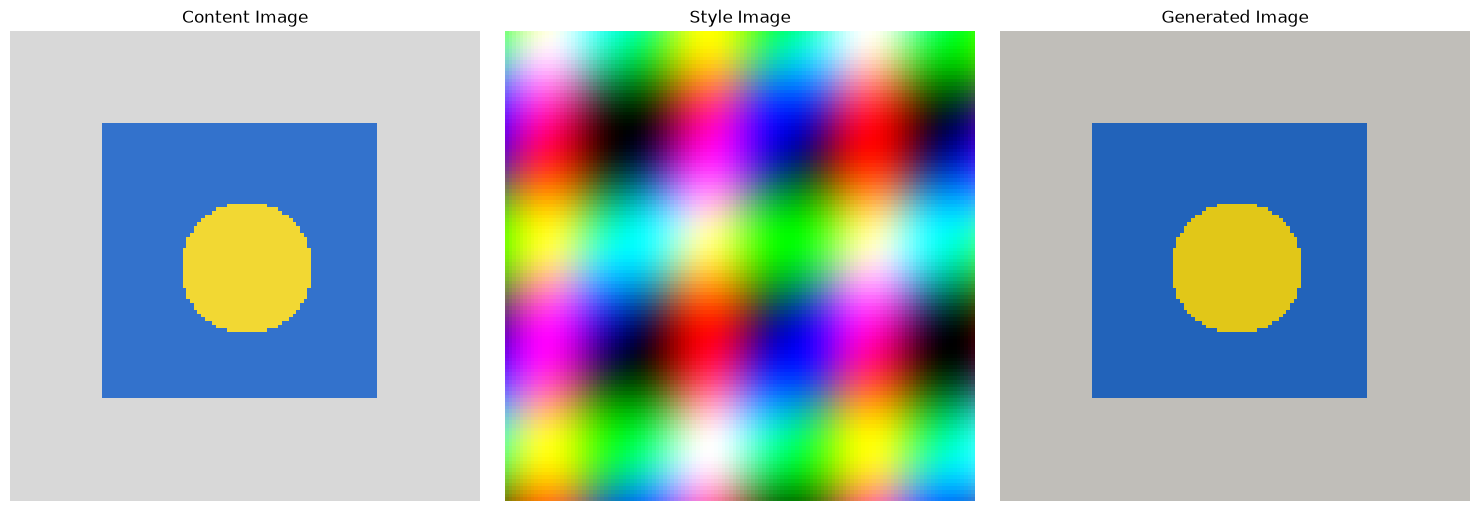

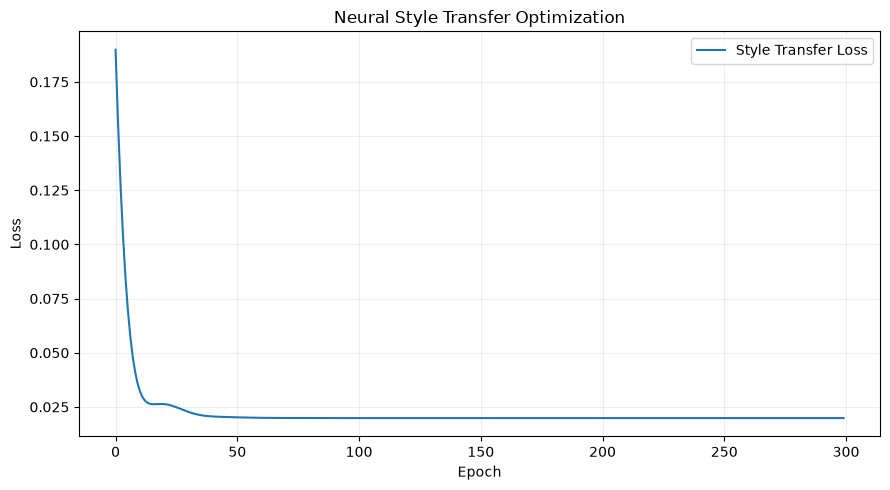


Generated image saved as:
practical_7_generated_style.png

OBSERVATION:
1. Neural Style Transfer separates content and style information.
2. Content loss helps preserve the structure of the content image.
3. Style loss uses feature correlations to represent artistic style.
4. The generated image is optimized to minimize both losses.
5. The final image combines content structure with style characteristics.

CONCLUSION:
Neural Style Transfer was successfully demonstrated using PyTorch. The experiment showed how content and style representations can be combined to create a new generated image. The practical also demonstrated the role of content loss and Gram-matrix-based style loss.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn.functional as F


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

np.random.seed(42)
torch.manual_seed(42)


# ============================================================
# 2. CREATE DEMONSTRATION IMAGES
# ============================================================

def create_content_image(size=128):
    """Create a simple content image with geometric structure."""

    image = np.zeros((size, size, 3), dtype=np.float32)

    # Background
    image[:] = [0.85, 0.85, 0.85]

    # Large square
    image[25:100, 25:100] = [0.2, 0.45, 0.8]

    # Center circle
    y, x = np.ogrid[:size, :size]
    mask = (x - 64) ** 2 + (y - 64) ** 2 < 18 ** 2
    image[mask] = [0.95, 0.85, 0.2]

    return image


def create_style_image(size=128):
    """Create a colorful patterned style image."""

    image = np.zeros((size, size, 3), dtype=np.float32)

    for y in range(size):
        for x in range(size):
            image[y, x, 0] = (np.sin(x / 7.0) + 1) / 2
            image[y, x, 1] = (np.cos(y / 9.0) + 1) / 2
            image[y, x, 2] = (np.sin((x + y) / 12.0) + 1) / 2

    return image


content_np = create_content_image()
style_np = create_style_image()


# ============================================================
# 3. CONVERT TO TENSORS
# ============================================================

content = torch.tensor(
    content_np,
    dtype=torch.float32
).permute(2, 0, 1).unsqueeze(0)

style = torch.tensor(
    style_np,
    dtype=torch.float32
).permute(2, 0, 1).unsqueeze(0)


# ============================================================
# 4. STYLE REPRESENTATION
# ============================================================

def gram_matrix(tensor):
    """
    Compute Gram Matrix.

    The Gram Matrix represents correlations between feature
    channels and is commonly used for style representation.
    """

    batch, channels, height, width = tensor.shape

    features = tensor.view(
        batch,
        channels,
        height * width
    )

    gram = torch.bmm(
        features,
        features.transpose(1, 2)
    )

    return gram / (channels * height * width)


# ============================================================
# 5. CONTENT AND STYLE FEATURES
# ============================================================

content_features = content

style_features = gram_matrix(style)


# ============================================================
# 6. INITIALIZE GENERATED IMAGE
# ============================================================

generated = torch.rand_like(content)

generated.requires_grad_(True)


# ============================================================
# 7. OPTIMIZER
# ============================================================

optimizer = torch.optim.Adam(
    [generated],
    lr=0.05
)


# ============================================================
# 8. STYLE TRANSFER OPTIMIZATION
# ============================================================

epochs = 300

content_weight = 1.0

style_weight = 5.0

loss_history = []

print("=" * 60)
print("PRACTICAL 7: NEURAL STYLE TRANSFER")
print("=" * 60)

print("Image size:", "128 x 128")

print("Optimization epochs:", epochs)

print()


for epoch in range(epochs):

    optimizer.zero_grad()

    # Content loss
    content_loss = F.mse_loss(
        generated,
        content_features
    )

    # Style loss
    generated_style = gram_matrix(generated)

    style_loss = F.mse_loss(
        generated_style,
        style_features
    )

    # Total loss
    total_loss = (
        content_weight * content_loss
        + style_weight * style_loss
    )

    total_loss.backward()

    optimizer.step()

    # Keep pixels between 0 and 1
    with torch.no_grad():
        generated.clamp_(0.0, 1.0)

    loss_history.append(
        total_loss.item()
    )

    if (epoch + 1) % 50 == 0:

        print(
            f"Epoch [{epoch + 1:3d}/{epochs}] | "
            f"Content Loss: {content_loss.item():.6f} | "
            f"Style Loss: {style_loss.item():.6f} | "
            f"Total Loss: {total_loss.item():.6f}"
        )


# ============================================================
# 9. CONVERT GENERATED IMAGE
# ============================================================

generated_np = (
    generated.detach()
    .squeeze(0)
    .permute(1, 2, 0)
    .numpy()
)


# ============================================================
# 10. DISPLAY CONTENT, STYLE AND GENERATED IMAGE
# ============================================================

plt.figure(figsize=(15, 5))


plt.subplot(1, 3, 1)

plt.imshow(content_np)

plt.title("Content Image")

plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(style_np)

plt.title("Style Image")

plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(generated_np)

plt.title("Generated Image")

plt.axis("off")


plt.tight_layout()

plt.show()


# ============================================================
# 11. LOSS GRAPH
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    loss_history,
    label="Style Transfer Loss"
)

plt.title("Neural Style Transfer Optimization")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(alpha=0.2)

plt.tight_layout()

plt.show()


# ============================================================
# 12. SAVE GENERATED IMAGE
# ============================================================

output_image = (
    np.clip(generated_np, 0, 1) * 255
).astype(np.uint8)

Image.fromarray(
    output_image
).save(
    "practical_7_generated_style.png"
)


print()
print("Generated image saved as:")
print("practical_7_generated_style.png")


# ============================================================
# 13. OBSERVATION
# ============================================================

print()
print("OBSERVATION:")

print(
    "1. Neural Style Transfer separates content and style information."
)

print(
    "2. Content loss helps preserve the structure of the content image."
)

print(
    "3. Style loss uses feature correlations to represent artistic style."
)

print(
    "4. The generated image is optimized to minimize both losses."
)

print(
    "5. The final image combines content structure with style characteristics."
)


# ============================================================
# 14. CONCLUSION
# ============================================================

print()
print("CONCLUSION:")

print(
    "Neural Style Transfer was successfully demonstrated using PyTorch. "
    "The experiment showed how content and style representations can be "
    "combined to create a new generated image. The practical also "
    "demonstrated the role of content loss and Gram-matrix-based style loss."
)